# LAB1 - Phần 2 - Bài 2 (Trang 37, 38): Luật kết hợp trên dữ liệu Online Retail
**Phạm Quốc Thuận - 6451071076 - CNTT.64**

In [1]:
# Cài thư viện (chỉ cần chạy 1 lần): pip install mlxtend openpyxl
import pandas as pd
import matplotlib.pyplot as plt
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)

## Câu 1: Đọc dữ liệu vào chương trình

In [2]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df = pd.read_excel('../Dataset/Online Retail.xlsx')   # file lớn, đọc mất khoảng 1 phút
print('Kích thước dữ liệu:', df.shape)
display(df.head())
df.info()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Kích thước dữ liệu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## Câu 2: Cắt ký tự thừa ở Description, xóa dòng không có InvoiceNo, chuyển InvoiceNo về chuỗi

In [3]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df['Description'] = df['Description'].str.strip()
df = df.dropna(axis=0, subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
print('Kích thước sau khi làm sạch:', df.shape)
df.head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Kích thước sau khi làm sạch: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


## Câu 3: Xóa các hóa đơn tín dụng (InvoiceNo chứa ký tự 'C')

In [4]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
display(df[df['InvoiceNo'].str.contains('C')].head())
print('Số dòng hóa đơn tín dụng:', df['InvoiceNo'].str.contains('C').sum())
df = df[~df['InvoiceNo'].str.contains('C')]
print('Kích thước sau khi xóa:', df.shape)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Số dòng hóa đơn tín dụng: 9288


Kích thước sau khi xóa: (532621, 8)


## Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64


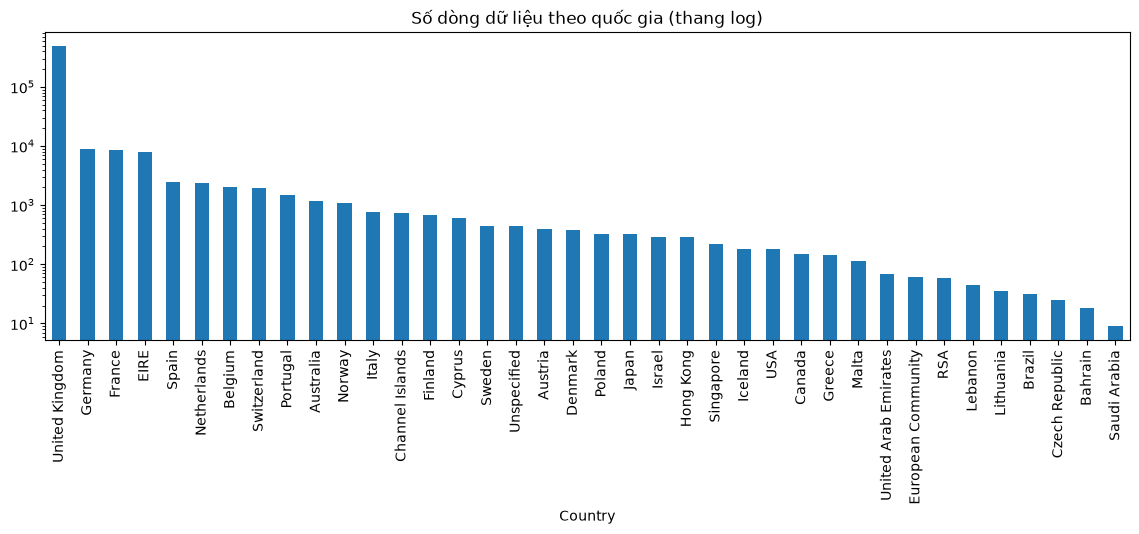

In [5]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
country_counts = df['Country'].value_counts()
print(country_counts.head(10))
country_counts.plot(kind='bar', figsize=(14, 4), logy=True, title='Số dòng dữ liệu theo quốc gia (thang log)')
plt.show()

## Câu 5: Lấy hóa đơn từ 'United Kingdom', gom nhóm Quantity theo InvoiceNo và Description

In [6]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
COUNTRY = 'United Kingdom'
grouped = (df[df['Country'] == COUNTRY]
           .groupby(['InvoiceNo', 'Description'])['Quantity'].sum())
print('Số dòng sau khi gom nhóm:', len(grouped))
grouped.head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Số dòng sau khi gom nhóm: 475560


InvoiceNo  Description                        
536365     CREAM CUPID HEARTS COAT HANGER          8
           GLASS STAR FROSTED T-LIGHT HOLDER       6
           KNITTED UNION FLAG HOT WATER BOTTLE     6
           RED WOOLLY HOTTIE WHITE HEART.          6
           SET 7 BABUSHKA NESTING BOXES            2
           WHITE HANGING HEART T-LIGHT HOLDER      6
           WHITE METAL LANTERN                     6
536366     HAND WARMER RED POLKA DOT               6
           HAND WARMER UNION JACK                  6
536367     ASSORTED COLOUR BIRD ORNAMENT          32
Name: Quantity, dtype: int64

## Câu 6: Chuyển dữ liệu về dạng hot encoding (mỗi dòng là một hóa đơn)

In [7]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
basket = grouped.unstack().reset_index().fillna(0).set_index('InvoiceNo')
print('Kích thước basket (số hóa đơn x số mặt hàng):', basket.shape)
basket.iloc[:5, :8]

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Kích thước basket (số hóa đơn x số mặt hàng): (18667, 4175)


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Câu 7: Chuyển từ hot encoding sang one-hot encoding

In [8]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
def encode_units(x):
    return 1 if x > 0 else 0

basket_sets = basket.map(encode_units).astype(bool)
basket_sets.iloc[:5, :8]

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


## Câu 8: Xóa cột 'POSTAGE'

In [9]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
print('Có cột POSTAGE:', 'POSTAGE' in basket_sets.columns)
basket_sets = basket_sets.drop(columns=['POSTAGE'], errors='ignore')
print('Kích thước sau khi xóa:', basket_sets.shape)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Có cột POSTAGE: True
Kích thước sau khi xóa: (18667, 4174)


## Câu 9: Tìm tập phổ biến bằng Apriori với min_sup = 3%

In [10]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
MIN_SUP = 0.03
start = time.time()
frequent_itemsets = apriori(basket_sets, min_support=MIN_SUP, use_colnames=True)
apriori_time = time.time() - start
print('Số tập phổ biến tìm được:', len(frequent_itemsets), '| thời gian: %.3f s' % apriori_time)
frequent_itemsets.sort_values('support', ascending=False).head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Số tập phổ biến tìm được: 131 | thời gian: 0.447 s


,support,itemsets
118,0.116034,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
52,0.103820,frozenset({JUMBO BAG RED RETROSPOT})
95,0.090266,frozenset({REGENCY CAKESTAND 3 TIER})
84,0.085391,frozenset({PARTY BUNTING})
69,0.074570,frozenset({LUNCH BAG RED RETROSPOT})
7,0.073445,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
103,0.066481,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
75,0.065302,frozenset({NATURAL SLATE HEART CHALKBOARD})
63,0.065142,frozenset({LUNCH BAG BLACK SKULL.})
35,0.062356,frozenset({HEART OF WICKER SMALL})


## Câu 10: Tạo luật kết hợp với min_conf = 50% và in ra các luật

In [11]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
MIN_CONF = 0.5
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=MIN_CONF)
rules['antecedents'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules['consequents'] = rules['consequents'].apply(lambda x: ', '.join(sorted(x)))
print('Số luật tìm được:', len(rules))
for i, r in rules.sort_values('confidence', ascending=False).iterrows():
    print(f"{r['antecedents']}  =>  {r['consequents']}   (sup={r['support']:.3f}, conf={r['confidence']:.3f}, lift={r['lift']:.2f})")

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số luật tìm được: 10
PINK REGENCY TEACUP AND SAUCER  =>  GREEN REGENCY TEACUP AND SAUCER   (sup=0.031, conf=0.821, lift=16.40)
GREEN REGENCY TEACUP AND SAUCER  =>  ROSES REGENCY TEACUP AND SAUCER   (sup=0.038, conf=0.751, lift=14.64)
ROSES REGENCY TEACUP AND SAUCER  =>  GREEN REGENCY TEACUP AND SAUCER   (sup=0.038, conf=0.732, lift=14.64)
JUMBO BAG PINK POLKADOT  =>  JUMBO BAG RED RETROSPOT   (sup=0.042, conf=0.677, lift=6.52)
ALARM CLOCK BAKELIKE GREEN  =>  ALARM CLOCK BAKELIKE RED   (sup=0.030, conf=0.643, lift=12.90)
JUMBO  BAG BAROQUE BLACK WHITE  =>  JUMBO BAG RED RETROSPOT   (sup=0.031, conf=0.626, lift=6.03)
GREEN REGENCY TEACUP AND SAUCER  =>  PINK REGENCY TEACUP AND SAUCER   (sup=0.031, conf=0.618, lift=16.40)
JUMBO STORAGE BAG SUKI  =>  JUMBO BAG RED RETROSPOT   (sup=0.037, conf=0.618, lift=5.95)
ALARM CLOCK BAKELIKE RED  =>  ALARM CLOCK BAKELIKE GREEN   (sup=0.030, conf=0.605, lift=12.90)
JUMBO SHOPPER VINTAGE RED PAI

## Câu 11: Biểu diễn độ hỗ trợ và độ tin cậy của tập luật bằng scatter plot

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


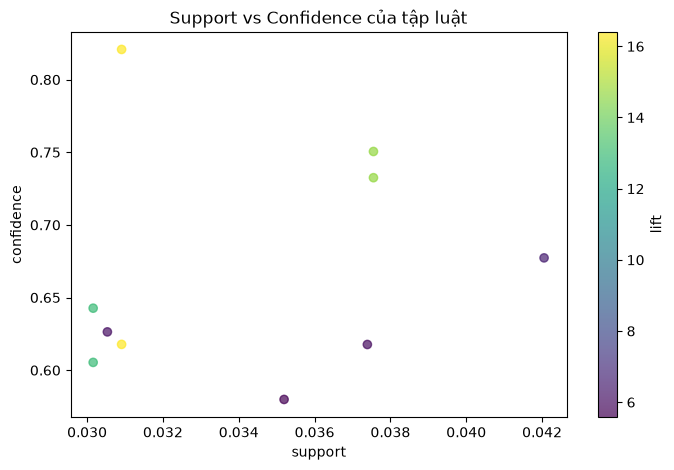

In [12]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
support = rules['support'].values
confidence = rules['confidence'].values
plt.figure(figsize=(8, 5))
plt.scatter(support, confidence, alpha=0.7, c=rules['lift'], cmap='viridis')
plt.colorbar(label='lift')
plt.xlabel('support'); plt.ylabel('confidence'); plt.title('Support vs Confidence của tập luật')
plt.show()

## Câu 12: FP-Growth với min_sup = 3%, min_conf = 50% và so sánh với Apriori

In [13]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
start = time.time()
fp_itemsets = fpgrowth(basket_sets, min_support=MIN_SUP, use_colnames=True)
fp_time = time.time() - start
fp_rules = association_rules(fp_itemsets, metric='confidence', min_threshold=MIN_CONF)
print('FP-Growth: %d tập phổ biến, %d luật, thời gian %.3f s' % (len(fp_itemsets), len(fp_rules), fp_time))
print('Apriori  : %d tập phổ biến, %d luật, thời gian %.3f s' % (len(frequent_itemsets), len(rules), apriori_time))
same = set(fp_itemsets['itemsets']) == set(frequent_itemsets['itemsets'])
print('Hai thuật toán cho cùng tập phổ biến:', same)
fp_rules['antecedents'] = fp_rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
fp_rules['consequents'] = fp_rules['consequents'].apply(lambda x: ', '.join(sorted(x)))
fp_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values('confidence', ascending=False)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


FP-Growth: 131 tập phổ biến, 10 luật, thời gian 1.744 s
Apriori  : 131 tập phổ biến, 10 luật, thời gian 0.447 s
Hai thuật toán cho cùng tập phổ biến: True


,antecedents,consequents,support,confidence,lift
9,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.030910,0.820768,16.403939
7,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.037553,0.750535,14.639752
6,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.037553,0.732497,14.639752
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.042053,0.677308,6.523895
4,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.030160,0.642694,12.900183
2,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.030535,0.626374,6.033290
8,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.030910,0.617773,16.403939
1,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.037392,0.617699,5.949737
5,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.030160,0.605376,12.900183
3,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.035196,0.579876,5.585425


**Nhận xét & So sánh:**
- Cả hai thuật toán **Apriori** và **FP-Growth** với `min_sup = 3%`, `min_conf = 50%` trên dữ liệu khách hàng Vương quốc Anh (`United Kingdom` - 18.667 hóa đơn, 4.174 mặt hàng sau khi bỏ `POSTAGE`) đều cho kết quả **hoàn toàn giống nhau**: **131 tập phổ biến** và **10 luật kết hợp**.
- Các luật có độ tin cậy và độ nâng (`lift`) rất cao đều rơi vào các mặt hàng mua theo bộ hoặc cùng dòng sản phẩm nhưng khác màu sắc/họa tiết, tiêu biểu:
  - `PINK REGENCY TEACUP AND SAUCER => GREEN REGENCY TEACUP AND SAUCER` (`conf = 82,1%`, `lift = 16,40`).
  - `GREEN REGENCY TEACUP AND SAUCER <=> ROSES REGENCY TEACUP AND SAUCER` (`conf = 75,1%` và `73,2%`, `lift = 14,64`).
  - Các mẫu túi `JUMBO BAG` và đồng hồ báo thức `ALARM CLOCK BAKELIKE` xanh - đỏ thường được khách mua kèm nhau.
- Về thời gian: với ngưỡng `min_sup = 3%` khá cao (chỉ sinh tập phổ biến ngắn 1–2 phần tử), Apriori với phép toán ma trận vector hóa của NumPy trong `mlxtend` chạy rất nhanh (~0,45 giây), tương đương hoặc nhỉnh hơn FP-Growth (~1,74 giây do chi phí dựng cây FP ban đầu trên ma trận 18.667 × 4.174).